# Question
What is the average number of turns that it takes to buy the "Boardwalk" property in Monopoly (If you get 200M every time you pass "GO")? How far away from that average is the median number of turns it takes to buy Boardwalk?

1. The random variable I am simulating is the number of turns it takes to reach the "Boardwalk" property after gaining enough money to buy it.
2. One trial will involve rolling two dice as many times as needed to first reach 400 dollars (by circling the whole board), then rolling the dice as many times as needed to land on the "Boardwalk" property. The possible outcomes are any number of turns.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [42]:
#constant variables:

total_spaces = 40
bwlk = 39 # boardwalk is in the 39th space of the monopoly board
bwlk_price = 400 # money needed to buy Boardwalk

In [43]:
#let's define rolling the dice enough times to get 200 dollars first and counting number of rolls
#This is just to accumulate enough money, will reach Boardwalk later

def simulate_board_game():
    position = 0          # Current space on the board (0 to 39)
    cash = 0              # Total money collected
    total_rolls = 0       # Total dice rolls taken
    circuit_count = 0     # Number of completed circuits
    
    circuit_data = []     # Data recorded every time a circuit is completed
    overshoot_spaces = 0  # Spaces past position 40 on the final circuit

    while cash < bwlk_price:
        total_rolls += 1
        die1, die2 = np.random.randint(1, 7, size=2)
        roll_total = die1 + die2
        
        position += roll_total
        
        if position >= total_spaces:
            circuit_count += 1
            cash += 200
            overshoot = position - total_spaces
            
            circuit_data.append({
                'Circuit': circuit_count,
                'Total Rolls Taken': total_rolls,
                'Overshoot Spaces': overshoot,
                'Total Cash ($)': cash
            })
            
            position = overshoot
            
            if cash >= bwlk_price:
                overshoot_spaces = overshoot

    df_circuits = pd.DataFrame(circuit_data)
    return df_circuits, overshoot_spaces

In [44]:
#once we do that, let's move onto defining landing on "Boardwalk" to buy it, adding to the Circuit Summary Dataframe created above

def land_on_space(df_summary, current_position, bwlk=39):
    # Initialize state from previous simulation
    position = current_position
    
    # Extract ending values from df_summary
    circuit_count = df_summary['Circuit'].iloc[-1]
    total_rolls = df_summary['Total Rolls Taken'].iloc[-1]
    cash = df_summary['Total Cash ($)'].iloc[-1]
    
    landed = False
    new_rows = []

    while not landed:
        total_rolls += 1
        die1, die2 = np.random.randint(1, 7, size=2)
        roll_total = die1 + die2
        
        position += roll_total

        # Exact match check before board wrap-around
        if position == bwlk:
            landed = True
            cash -= bwlk_price
            # Record final stop event
            new_rows.append({
                'Circuit': circuit_count,
                'Total Rolls Taken': total_rolls,
                'Overshoot Spaces': position - bwlk, # 0 spaces past Boardwalk
                'Total Cash ($)': cash
            })
            break

        # If we cross or reach space 40 without an exact hit on Boardwalk
        if position >= total_spaces:
            circuit_count += 1
            cash += 200  # Collect $200 for wrapping around the board
            overshoot = position - total_spaces
            
            new_rows.append({
                'Circuit': circuit_count,
                'Total Rolls Taken': total_rolls,
                'Overshoot Spaces': overshoot,
                'Total Cash ($)': cash
            })
            
            # Carry over extra spaces and check if overshoot lands directly on Boardwalk
            position = overshoot
            if position == bwlk:
                landed = True
                cash -= 400
                new_rows[-1]['Total Cash ($)'] = cash
                break

    # Append new rows to the existing dataframe
    updated_df = pd.concat([df_summary, pd.DataFrame(new_rows)], ignore_index=True)
    return updated_df

In [6]:
#now let's combine both functions into one big function

def monopoly_simulation(num_simulations=10000, bwlk=39):
    total_turns_list = []

    for _ in range(num_simulations):
        # Stage 1: Reach $400
        df_summary, start_position = simulate_board_game()
        
        # Stage 2: Land on Boardwalk
        final_df = land_on_space(df_summary, current_position=start_position, bwlk=bwlk)
        
        # Record final roll count for this trial
        final_turns = final_df['Total Rolls Taken'].iloc[-1]
        total_turns_list.append(final_turns)

    return np.array(total_turns_list)

In [ ]:
# --- Run Monopoly Simulation ---
N_TRIALS = 10000
BWLK_SPACE = bwlk

turns_data = monopoly_simulation(num_simulations=N_TRIALS, bwlk=BWLK_SPACE)

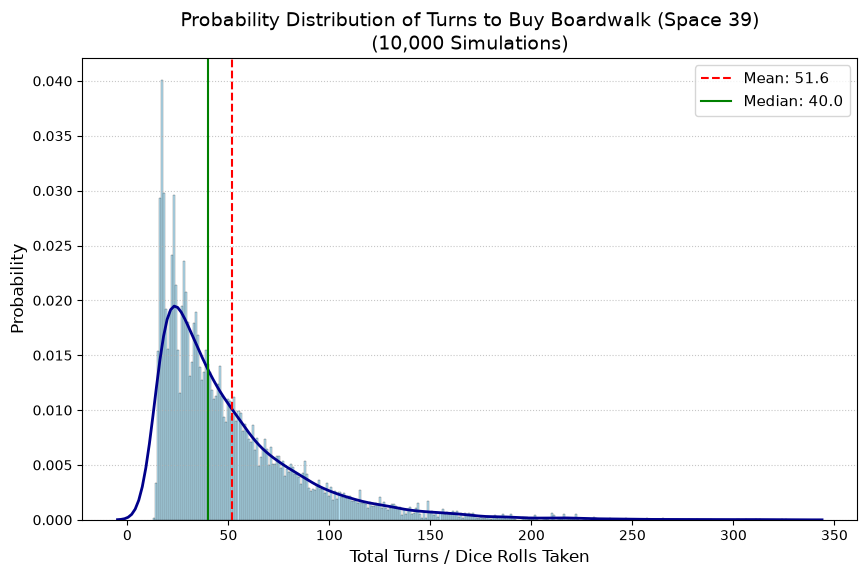

In [8]:
# --- Plotting Probability Distribution ---
plt.figure(figsize=(10, 6))

# Histogram with kernel density estimation (KDE) line
sns.histplot(turns_data, stat="probability", discrete=True, color="skyblue", edgecolor="black", alpha=0.6)
sns.kdeplot(turns_data, color="darkblue", linewidth=2) ####

plt.title(f"Probability Distribution of Turns to Buy Boardwalk (Space {BWLK_SPACE})\n({N_TRIALS:,} Simulations)", fontsize=14)
plt.xlabel("Total Turns / Dice Rolls Taken", fontsize=12)
plt.ylabel("Probability", fontsize=12)

# Mark summary statistics on graph
mean_turns = np.mean(turns_data)
median_turns = np.median(turns_data)

plt.axvline(mean_turns, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean_turns:.1f}')
plt.axvline(median_turns, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median_turns:.1f}')

plt.legend(fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.show()

In [35]:
expected_value = mean_turns
print(expected_value)

51.5764


In [15]:
standard_dev = turns_data.std()
print(standard_dev)

37.62900162162158


In [36]:
median = median_turns
print(median)

40.0


In [37]:
# Calculate z-score
z_score = (median - expected_value)/standard_dev
print(z_score)

-0.30764568553815186


# Conclusion
##### 1. The average number of turns it takes to buy the Boardwalk property is 52 turns. The median is 0.31 standard deviations less than the mean, meaning that it is pretty close to the mean relative to how far apart the values are from each other. This also means that the distribution of the number of turns is skewed right. However, the standard deviation is 37.6, so the distribution is fairly spread out.
##### 2. Graph included couple cells above.
##### 3. The graph shows that although the highest probability of turns is around 25 turns, the mean and median are closer to 50. This is because there a lot of "Total Turns" values with small probabilities towards the right end of the graph. Releative to the range, the mean and median are fairly close to each other, the median being less than the mean. Therefore, it is also clear that the graph is skewed right. Looking at the probabilities, it is also reasonable to say that buying the Boardwalk property will more likely take less than 52 turns than it will more than 52 turns.